In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re
from pathlib import Path

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_pickle('../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 10]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
0,E162956,2018-10-01,0.47,0.48,0.46,0.39,0.51,0.57,0.45,0.36,0.44,0.44,0.44,0.41,0.43,0.41,0.39,0.63,0.41,0.47,0.51,0.68,0.60,0.65,0.70,0.83,1.02,0.87,0.82,0.88,0.88,0.91,0.89,1.07,1.26,1.26,1.15,1.07,0.90,0.88,0.87,0.86,0.64,0.59,0.76,0.62,0.70,0.58,0.46,0.54,46.0,POINT (-84.30334 30.388433),1801,18011011
1,E162956,2018-10-02,0.51,0.49,0.48,0.47,0.65,0.46,0.41,0.46,0.40,0.37,0.73,1.20,0.44,0.47,0.36,0.38,0.38,0.54,0.41,0.52,0.48,0.54,0.69,0.75,0.73,1.02,0.86,0.87,0.81,0.87,0.86,0.87,1.31,1.56,2.10,3.21,1.56,1.03,1.02,0.90,1.08,1.38,2.18,1.74,1.23,1.16,0.77,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011


In [4]:
df['badge'].nunique()


55388

In [5]:
# 48 个半小时列（按时间排序）
value_cols = sorted(
    [c for c in df.columns if c.startswith("INT_VALUE_")],
    key=lambda c: int(c.split("_")[-1]),
)
assert len(value_cols) == 48

meta_cols = ["address", "district", "tractID", "blockID"]

# 日期统一到“天”
df["date"] = pd.to_datetime(df["date"], errors="coerce").dt.normalize()

# 同一天同一 badge 若有多条，先合并（按你业务选 sum / mean / first）
df = (
    df.groupby(["badge", "date"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(df["badge"].unique())

# 30 个日历日：按你的需求改起止日
day_range = pd.date_range("2018-10-01", periods=30, freq="D").normalize()
# 若要对齐整个 10 月（31 天），可改为：
# day_range = pd.date_range("2018-10-01", "2018-10-31", freq="D").normalize()

# 构造 badge × day 的完整网格
idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "date"])

df_full = (
    df.set_index(["badge", "date"])[value_cols + meta_cols]
    .reindex(idx)  # 缺的 (badge, day) 整行变成 NaN
)

# 数值列：NaN → 0（含“补出来的整天”）
df_full[value_cols] = (
    df_full[value_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
)

# 元数据列：用每个 badge 的第一条非空记录向前填
df_full[meta_cols] = df_full.groupby(level=0)[meta_cols].transform(
    lambda s: s.ffill().bfill()
)

df = df_full.reset_index()
df.index = range(df.shape[0])

# 自检：每个 badge 恰好 30 天
assert df.groupby("badge").size().eq(len(day_range)).all()

In [6]:
value_cols = sorted(
    [c for c in df.columns if c.startswith("INT_VALUE_")],
    key=lambda c: int(c.split("_")[-1]),
)
n_slots = 30 * len(value_cols)  # 30 * 48 = 1440
# 每个 badge 在整月上的 0 占比
df_badge_zero = (
    df.groupby("badge")[value_cols]
    .apply(lambda g: (g == 0).to_numpy().sum() / (g.shape[0] * len(value_cols)))
    .reset_index(name="zero_ratio")
)


In [7]:
# 只保留 zero_ratio <= 0.25 的 badge
df_badge_zero = df_badge_zero[df_badge_zero["zero_ratio"] <= 0.25].reset_index(drop=True)
badges_keep = df_badge_zero["badge"]
df = df[df["badge"].isin(badges_keep)].reset_index(drop=True)
print(df['badge'].nunique())
df.head()

52162


,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
0,E162956,2018-10-01,0.47,0.48,0.46,0.39,0.51,0.57,0.45,0.36,0.44,0.44,0.44,0.41,0.43,0.41,0.39,0.63,0.41,0.47,0.51,0.68,0.60,0.65,0.70,0.83,1.02,0.87,0.82,0.88,0.88,0.91,0.89,1.07,1.26,1.26,1.15,1.07,0.90,0.88,0.87,0.86,0.64,0.59,0.76,0.62,0.70,0.58,0.46,0.54,46.0,POINT (-84.30334 30.388433),1801,18011011
1,E162956,2018-10-02,0.51,0.49,0.48,0.47,0.65,0.46,0.41,0.46,0.40,0.37,0.73,1.20,0.44,0.47,0.36,0.38,0.38,0.54,0.41,0.52,0.48,0.54,0.69,0.75,0.73,1.02,0.86,0.87,0.81,0.87,0.86,0.87,1.31,1.56,2.10,3.21,1.56,1.03,1.02,0.90,1.08,1.38,2.18,1.74,1.23,1.16,0.77,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011
2,E162956,2018-10-03,0.52,0.62,0.45,0.46,0.54,0.49,0.42,0.45,0.45,0.35,1.46,0.73,0.59,0.39,0.34,0.51,0.42,0.39,0.42,0.49,0.54,0.69,0.64,0.71,0.73,0.82,0.81,0.89,0.88,1.03,0.88,0.82,0.88,0.91,1.41,1.06,0.87,0.69,0.67,0.63,0.75,1.78,2.15,1.38,0.64,0.69,0.55,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011
3,E162956,2018-10-04,0.50,0.49,0.57,0.50,0.46,0.55,0.45,0.42,0.43,0.53,0.96,0.96,0.51,0.38,0.51,0.38,0.37,0.39,0.51,0.41,0.49,0.54,0.61,0.68,0.97,0.88,0.88,0.87,0.83,0.88,0.89,1.03,0.88,0.83,0.88,0.95,0.89,0.93,0.75,0.66,0.83,1.33,0.93,0.58,0.62,0.47,0.48,2.13,46.0,POINT (-84.30334 30.388433),1801,18011011
4,E162956,2018-10-05,0.57,0.42,0.38,0.51,0.43,0.34,0.39,0.34,0.53,0.38,1.65,1.19,0.41,0.39,0.52,0.34,0.40,0.38,0.39,0.45,0.50,0.64,0.65,0.74,0.88,0.91,0.90,0.87,1.21,0.91,0.93,0.92,0.94,0.92,1.32,0.91,0.89,1.02,0.67,0.67,0.64,0.54,0.54,0.75,0.55,1.34,0.56,0.47,46.0,POINT (-84.30334 30.388433),1801,18011011


In [8]:
boundary_block = pd.read_csv('../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.index = range(boundary_block.shape[0])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [9]:
boundary_tract = pd.read_csv('../../Data/boundary_data/tal_tract_boundary.csv')
boundary_tract["geometry"] = geopd.GeoSeries.from_wkt(boundary_tract["geometry"])
boundary_tract = geopd.GeoDataFrame(boundary_tract, crs="EPSG:4326")
boundary_tract["centroid"] = geopd.GeoSeries.from_wkt(boundary_tract["centroid"])
boundary_tract.head(2)

,tractID,geoID,geometry,centroid
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473)
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882)


In [10]:
def household_count_by_zone(df, id_col="blockID"):
    """
    id_col: 'blockID' 或 'tractID'
    返回每个区域的去重 badge 数量
    """
    meta = df.drop_duplicates(subset=["badge"])[["badge", "blockID", "tractID"]]
    meta[id_col] = meta[id_col].astype(str)
    cnt = (
        meta.groupby(id_col, as_index=False)["badge"]
        .nunique()
        .rename(columns={"badge": "n_household"})
    )
    return cnt

In [11]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
def plot_household_heatmap_continuous(cnt_df, boundary_gdf, id_col="blockID", title=None, cmap="YlOrRd"):
    geo = geopd.GeoDataFrame(boundary_gdf.copy(), crs="EPSG:4326")
    geo[id_col] = geo[id_col].astype(str)
    geo = geo.merge(cnt_df, on=id_col, how="left")
    geo["n_household"] = geo["n_household"].fillna(0)
    vmin, vmax = 0, geo["n_household"].max()
    if vmax == vmin:
        vmax = vmin + 1
    norm = Normalize(vmin=vmin, vmax=vmax)
    fig, ax = plt.subplots(1, 1, figsize=(30, 18))
    geo.plot(
        ax=ax,
        column="n_household",
        cmap=cmap,           # 自带色带，如 "YlOrRd", "OrRd", "hot", "viridis"
        norm=norm,           # 连续映射；不要写 scheme / k
        legend=False,
        edgecolor="black",
        linewidth=0.4 if id_col == "blockID" else 0.8,
        missing_kwds={"color": "lightgrey"},
    )
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Number of households")
    ax.set_title(title or f"Household heatmap by {id_col}")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [12]:
def plot_household_count_curve(cnt_df, id_col="blockID", title=None):
    """各区域户数排序后的曲线（rank–count）"""
    y = np.sort(cnt_df["n_household"].to_numpy())
    x = np.arange(1, len(y) + 1)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(x, y, color="#D62728", lw=2)
    ax.fill_between(x, y, alpha=0.15, color="#FFA500")
    ax.set_xlabel(f"Rank (sorted by household count per {id_col})")
    ax.set_ylabel("Number of households (unique badges)")
    ax.set_title(title or f"Household count distribution by {id_col}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    # 可选：再看「户数」本身的直方图（有多少个 block 是 1 户、2 户…）
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(cnt_df["n_household"], bins=30, color="#FFA500", edgecolor="black", alpha=0.85)
    ax.set_xlabel(f"Households per {id_col}")
    ax.set_ylabel("Number of zones")
    ax.set_title(f"Histogram: households per {id_col}")
    plt.tight_layout()
    plt.show()

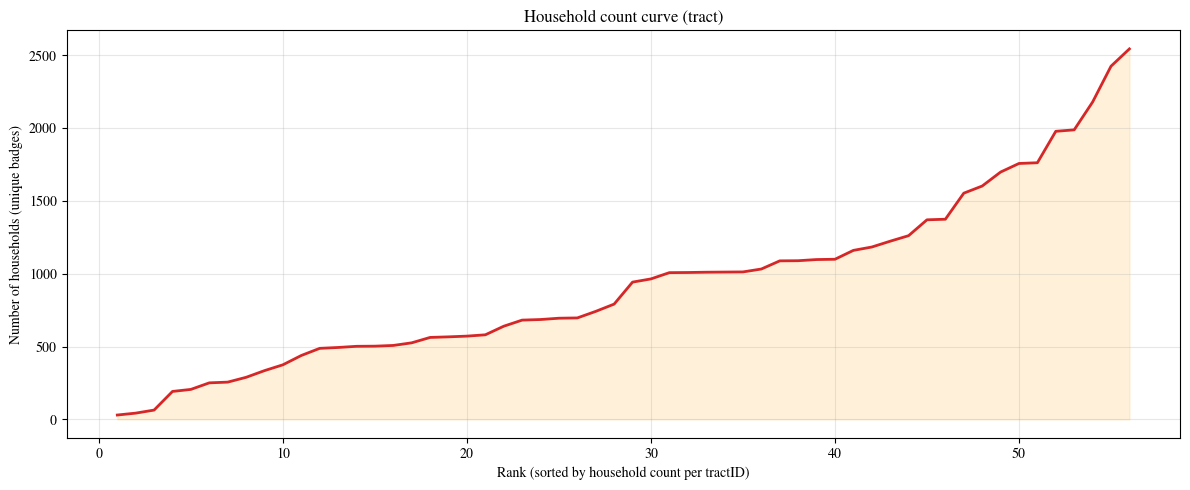

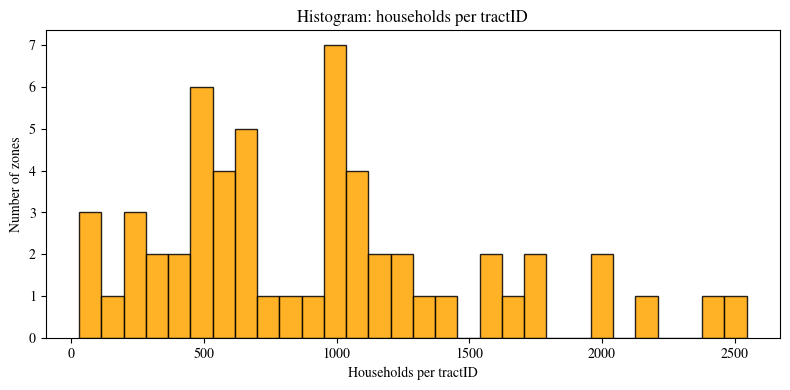

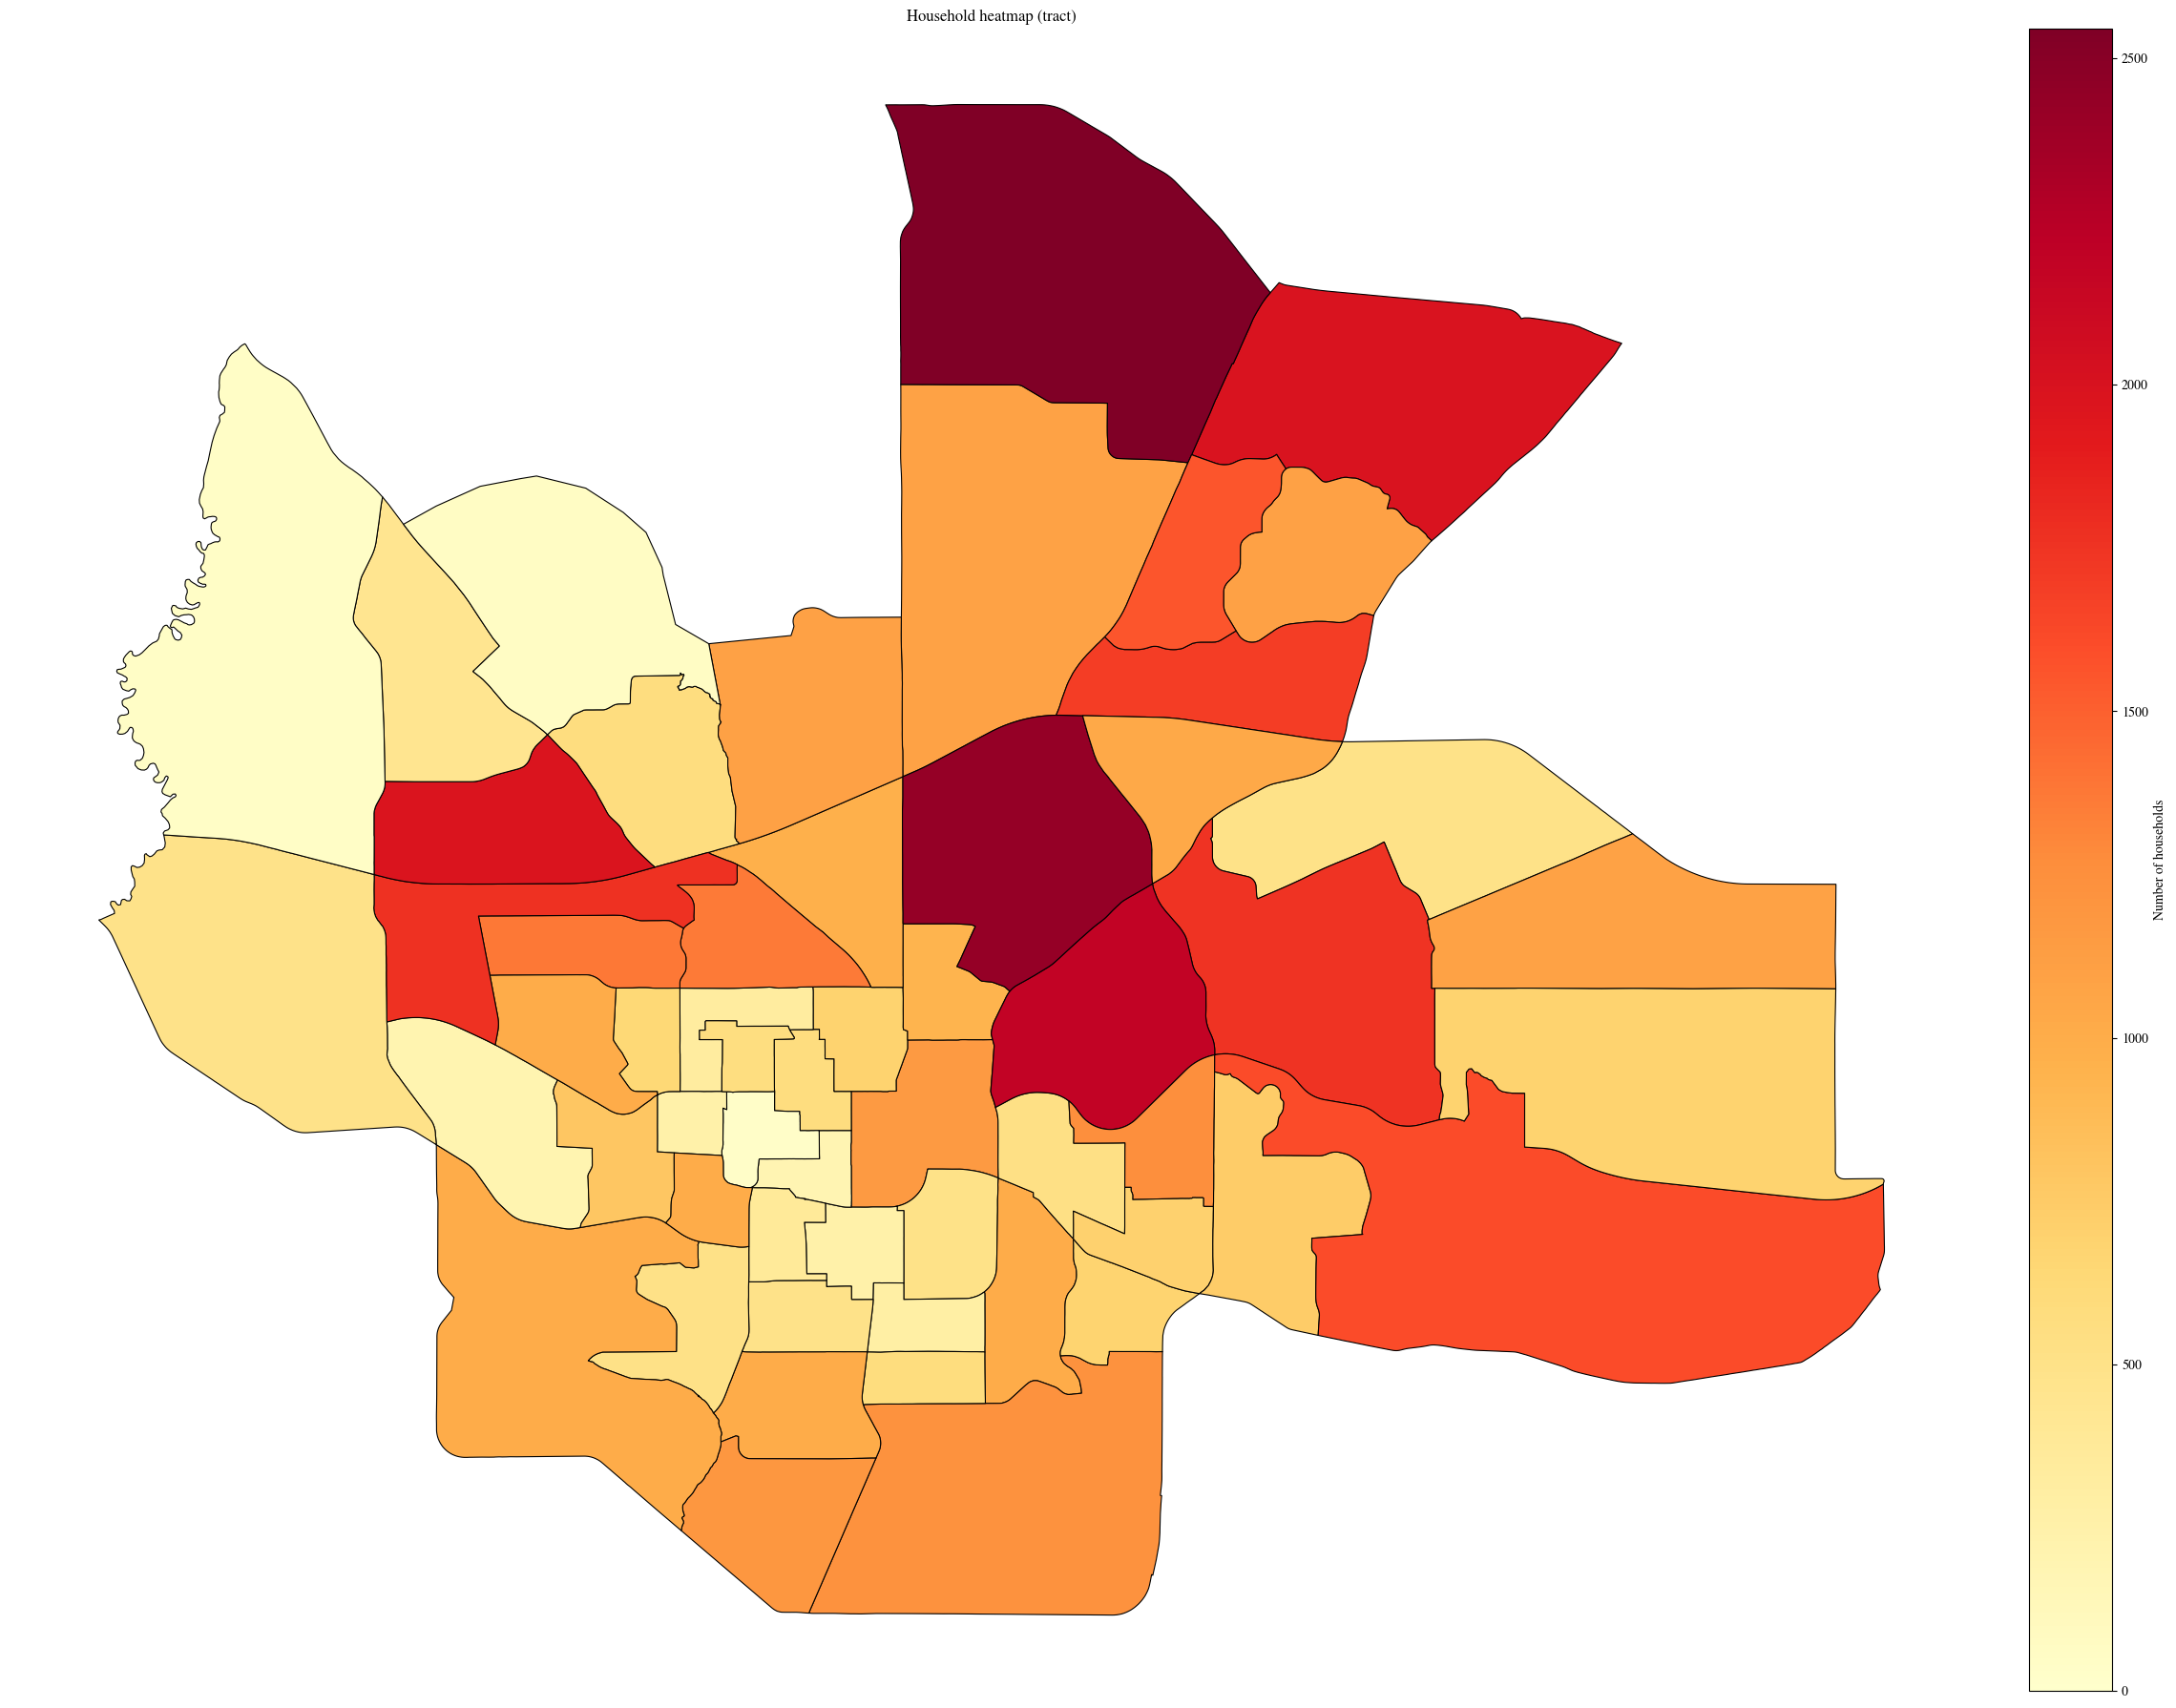

In [13]:
cnt_tract = household_count_by_zone(df, id_col="tractID")
plot_household_count_curve(cnt_tract, id_col="tractID",
    title="Household count curve (tract)")
geo_tract = plot_household_heatmap_continuous(
    cnt_tract,
    boundary_tract,
    id_col="tractID",
    title="Household heatmap (tract)",
)

In [14]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID"]

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [18]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID"]

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# 与前面 df 补齐的 30 天一致（2018-10-01 起）
day_range = pd.date_range("2018-10-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [19]:
value_cols_180 = [f"t{i:03d}" for i in range(180)]
badges_bad = (
    df2.groupby("badge")[value_cols_180]
    .max()
    .max(axis=1)  # 每个 badge 在 180 列上的最大值
    .pipe(lambda s: s[s > 100].index)
)
n_before = df2["badge"].nunique()
df2 = df2[~df2["badge"].isin(badges_bad)].reset_index(drop=True)
n_after = df2["badge"].nunique()
print(f"剔除任一 t* > 100 的户: {len(badges_bad)}")
print(f"badge 数: {n_before} -> {n_after}")

剔除任一 t* > 100 的户: 806
badge 数: 52162 -> 51356


In [20]:
df2

,badge,address,district,tractID,blockID,t000,t001,t002,t003,t004,t005,t006,t007,t008,t009,t010,t011,t012,t013,t014,t015,t016,t017,t018,t019,t020,t021,t022,t023,t024,t025,t026,t027,t028,t029,t030,t031,t032,t033,t034,t035,t036,t037,t038,t039,t040,t041,t042,t043,t044,t045,t046,t047,t048,t049,t050,t051,t052,t053,t054,t055,t056,t057,t058,t059,t060,t061,t062,t063,t064,t065,t066,t067,t068,t069,t070,t071,t072,t073,t074,t075,t076,t077,t078,t079,t080,t081,t082,t083,t084,t085,t086,t087,t088,t089,t090,t091,t092,t093,t094,t095,t096,t097,t098,t099,t100,t101,t102,t103,t104,t105,t106,t107,t108,t109,t110,t111,t112,t113,t114,t115,t116,t117,t118,t119,t120,t121,t122,t123,t124,t125,t126,t127,t128,t129,t130,t131,t132,t133,t134,t135,t136,t137,t138,t139,t140,t141,t142,t143,t144,t145,t146,t147,t148,t149,t150,t151,t152,t153,t154,t155,t156,t157,t158,t159,t160,t161,t162,t163,t164,t165,t166,t167,t168,t169,t170,t171,t172,t173,t174,t175,t176,t177,t178,t179
0,E162956,46.0,POINT (-84.30334 30.388433),1801,18011011,3.6900,3.5900,4.8500,7.3400,8.2500,4.8900,3.9300,4.3500,4.3100,6.8900,12.6900,10.2200,3.9500,4.8200,4.3000,6.8600,7.1200,8.6200,3.9400,4.6600,4.0000,7.2300,6.7700,7.3700,3.3800,5.4100,4.1500,7.5300,7.3400,5.3900,3.5100,3.120,5.3000,7.510,6.4800,4.2600,3.4200,3.0900,5.8500,7.4600,8.4200,6.8400,4.1900,6.4900,4.8000,6.2900,10.1300,1.1400,1.3200,1.1800,1.0900,1.2100,1.2000,1.1900,1.1000,1.2000,1.2000,0.5500,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.000,0.0000,0.0000,0.000,0.000,0.000,0.000,0.0000,0.0000,0.0000,0.000,5.4400,3.9400,2.9600,2.450,4.7700,8.6900,8.760,6.1000,3.4900,4.4800,4.2400,7.3700,15.1200,7.2200,4.160,5.0200,5.3500,7.5000,12.4800,7.3000,3.9000,4.9000,4.6200,7.2600,9.1800,5.8400,3.9600,4.7400,3.5600,7.0400,9.1200,5.6800,3.6300,4.4600,4.0100,7.1900,7.1700,3.7900,3.1500,3.1800,8.6900,7.8700,6.8600,4.7200,2.2800,2.3900,3.7500,2.8000,3.6300,3.2100,2.2500,3.820,2.1800,2.1600,4.1100,7.3300,2.1300,3.0000,3.5500,10.6900,3.7300,2.690,2.2600,2.4700,3.3200,3.4300,4.800,2.4700,2.1600,3.6400,2.210,2.1300,2.890,5.1200,1.2300,3.0600,1.3700,2.5300,5.0500,1.3800,1.310,1.2000,8.0200,4.6500,4.2100,3.3800,8.0100,12.1000,9.3300,2.8300,1.9500,2.010,4.2200,6.560,4.2100,1.3500,1.4600,1.4100,4.1100,7.8800,5.2800,1.1700,3.4300,1.9700
1,E162959,36.0,POINT (-84.2839 30.493797),1602,16022007,4.6000,7.0300,7.1500,12.8000,15.7300,11.9000,5.9700,7.0800,7.5000,13.0800,12.6900,7.4500,5.1100,10.0500,6.9600,12.9700,17.5800,9.0800,4.4800,6.2300,5.6600,11.7900,9.6300,16.0100,4.3900,10.0400,5.5000,12.3500,10.0400,6.4500,4.4200,3.490,5.4600,11.720,12.2300,8.4600,3.7900,3.7900,13.0700,21.9600,20.7400,9.8000,5.9100,12.3100,9.1500,12.2000,15.5100,9.8000,6.7400,9.6900,12.2000,16.1400,18.5800,11.6200,7.7200,6.0100,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.000,0.0000,0.000,0.0000,0.0000,0.000,0.000,0.000,0.000,0.0000,0.0000,0.0000,0.000,0.0000,0.0000,0.0000,0.000,0.0000,11.1100,20.360,6.1700,3.8700,10.0300,7.8500,15.5700,20.7900,11.5500,5.610,10.0300,9.8800,18.6600,14.9300,12.0000,5.3500,9.6400,6.7300,13.1700,27.3000,14.0600,6.4200,6.0200,5.7300,12.2200,17.2900,15.9300,3.6500,5.2000,5.5700,10.3900,12.8300,12.5500,2.9600,2.9800,5.6700,15.1500,16.7800,7.9000,3.1600,2.1000,3.8600,5.9400,11.1900,3.7700,2.5200,4.880,2.6000,3.7500,14.5700,6.9400,2.4100,7.3100,4.3300,4.7100,6.2900,2.420,2.2400,6.0500,3.6800,4.9200,12.440,3.7500,2.3200,7.0600,3.870,3.7700,15.750,3.0700,2.2400,6.8500,5.2200,12.5200,11.0500,6.2100,2.230,2.2200,8.8800,8.2300,8.6500,4.6300,1.9300,2.0000,7.0400,7.6700,7.8900,3.720,2.2500,10.200,4.3600,6.1200,13.8600,3.5200,2.1600,6.3100,3.5200,3.7200,7.1100,2.6300
2,E162961,32.0,POINT (-84.368385 30.461784),2304,23041037,4.2900,4.6800,6.0000,6.1400,10.0400,8.3600,4.5700,5.7300,6.0700,7.2400,8.1000,7.9200,4.4000,5.0600,5.5800,6.0400,9.1000,4.7700,4.2600,4.9200,9.1800,8.1000,12.1300,4.6100,4.0700,8.0800,8.9200,6.1400,10.2100,4.9300,4.5600,5.730,4.2500,5.710,5.6500,2.9300,2.6600,2.4700,18.4000,6.2900,6.6100,5.2100,5.0300,5.3200,3.3900,5.1900,12.7400,6.5900,4.4700,10

In [21]:
# ===== 从单个 tractID 抽取 100 个 badge =====
TARGET_TRACT = None      # 指定 tractID，如 "12073000100"；None 则自动选一个 badge 数 >= 100 的 tract
N_SAMPLE = 100
COND_VALUE = 1           # 同一 tract 下所有样本共用同一个 condition（例如 1）
RANDOM_STATE = 42
SAVE_DIR = Path("../SynEnergy/Data/Power")

value_cols_180 = [f"t{i:03d}" for i in range(180)]

meta = df2.drop_duplicates("badge").copy()
meta["tractID"] = meta["tractID"].astype(str)

tract_counts = meta.groupby("tractID")["badge"].nunique()
print(f"tract 总数: {tract_counts.shape[0]}")
print(f"badge 数 >= {N_SAMPLE} 的 tract 数: {(tract_counts >= N_SAMPLE).sum()}")

if TARGET_TRACT is None:
    eligible = tract_counts[tract_counts >= N_SAMPLE].index.tolist()
    if not eligible:
        raise ValueError(f"没有 tract 的 badge 数 >= {N_SAMPLE}")
    TARGET_TRACT = sorted(eligible, key=int)[0]
else:
    TARGET_TRACT = str(TARGET_TRACT)

pool = meta.loc[meta["tractID"] == TARGET_TRACT, "badge"].values
if len(pool) < N_SAMPLE:
    raise ValueError(f"tract {TARGET_TRACT} 只有 {len(pool)} 个 badge，不足 {N_SAMPLE}")

rng = np.random.default_rng(RANDOM_STATE)
selected = rng.choice(pool, size=N_SAMPLE, replace=False)

df_sampled = (
    df2[df2["badge"].isin(selected)]
    .drop_duplicates("badge")
    .set_index("badge")
    .loc[selected]
    .reset_index()
)

X = df_sampled[value_cols_180].to_numpy(dtype=np.float32)
X = np.expand_dims(X, axis=-1)  # (100, 180, 1)

# 同一 tract -> 所有样本 condition 相同
C = np.full((N_SAMPLE, 1, 1), COND_VALUE, dtype=np.int64)

print(f"tractID = {TARGET_TRACT}")
print(f"抽取 badge 数 = {len(selected)}")
print(f"X shape = {X.shape}, C shape = {C.shape}")
print(f"condition 唯一值 = {np.unique(C)}")

SAVE_DIR.mkdir(parents=True, exist_ok=True)
np.save(SAVE_DIR / "Tallahassee_seq_180_sample_100.npy", X)
np.save(SAVE_DIR / "Tallahassee_seq_180_sample_100_condition.npy", C)
print("已保存:")
print(" ", SAVE_DIR / "Tallahassee_seq_180_sample_100.npy")
print(" ", SAVE_DIR / "Tallahassee_seq_180_sample_100_condition.npy")

tract 总数: 56
badge 数 >= 100 的 tract 数: 53
tractID = 200
抽取 badge 数 = 100
X shape = (100, 180, 1), C shape = (100, 1, 1)
condition 唯一值 = [1]
已保存:
  ../SynEnergy/Data/Power/Tallahassee_seq_180_sample_100.npy
  ../SynEnergy/Data/Power/Tallahassee_seq_180_sample_100_condition.npy
